# Comparação dos resultados

Lê as saídas já geradas e salvas no Drive e produz as figuras da apresentação. Nada é treinado aqui.

```
Deteccao_Vozes/
  ├── saida_ml/          # notebook de KNN e SVM (trabalho de ML)
  ├── saida_baseline/    # notebook do baseline (regressão logística + limiar)
  └── saida_cnn/         # notebook das CNNs A e B
```

As figuras são salvas em `figuras_apresentacao/` (e copiadas para o Drive no fim).

**Atenção à comparação entre trabalhos:** o baseline e as CNNs (Redes Neurais) medem macro-F1 **dos 6 comandos**
com rejeição por limiar, mais FA e FR. O KNN e o SVM (ML) não têm limiar e tratam "fora" como 7ª classe.
Os números dos dois trabalhos ficam em figuras separadas e não devem ser comparados diretamente.

In [1]:
from google.colab import drive; drive.mount('/content/drive')
BASE = "/content/drive/MyDrive/Projetos/Deteccao_Vozes"

Mounted at /content/drive


In [2]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle

ML, BL, CN = f"{BASE}/saida_ml", f"{BASE}/saida_baseline", f"{BASE}/saida_cnn"
FIG = "figuras_apresentacao"; os.makedirs(FIG, exist_ok=True)
CONDS = ["limpo", "20dB", "10dB", "0dB"]
EIXO = ["Limpo", "20 dB", "10 dB", "0 dB"]

# Paleta e estilo comuns a todas as figuras
CORES = {"Baseline": "#8C8C8C", "CNN A": "#4C78A8", "CNN B": "#E45756",
         "KNN": "#72B7B2", "SVM": "#B279A2"}
MARC = {"Baseline": "s", "CNN A": "o", "CNN B": "D", "KNN": "o", "SVM": "s"}
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 12, "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.labelsize": 12, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linestyle": "-", "axes.axisbelow": True,
    "legend.frameon": False, "savefig.dpi": 220, "savefig.bbox": "tight", "figure.facecolor": "white"})

def salvar(nome):
    plt.savefig(f"{FIG}/{nome}.png"); plt.show()

# Resultados das redes neurais (baseline + CNNs)
rn = pd.concat([pd.read_csv(f"{BL}/resultados_baseline.csv"), pd.read_csv(f"{CN}/resultados_cnn.csv")], ignore_index=True)
# Usa o teste se ele já foi rodado nos dois notebooks; senão, a validação
PART = "teste" if {"Baseline", "CNN A", "CNN B"} <= set(rn.loc[rn.particao == "teste", "modelo"]) else "val"
NOME_PART = {"teste": "teste", "val": "validação"}[PART]
rn = rn[rn.particao == PART]
MOD_RN = ["Baseline", "CNN A", "CNN B"]
print(f"Partição usada nas redes neurais: {NOME_PART}")

resumo = (rn.groupby(["modelo", "cond"])[["macroF1", "FA", "FR"]].agg(["mean", "std"])
            .reindex(pd.MultiIndex.from_product([MOD_RN, CONDS])))
resumo.round(3)

Partição usada nas redes neurais: validação


macroF1            FA            FR       
                  mean    std   mean    std   mean    std
Baseline limpo   0.399  0.096  0.484  0.236  0.441  0.219
         20dB    0.332  0.085  0.509  0.252  0.497  0.196
         10dB    0.311  0.088  0.384  0.185  0.566  0.214
         0dB     0.223  0.089  0.258  0.156  0.618  0.188
CNN A    limpo   0.531  0.159  0.215  0.141  0.535  0.223
         20dB    0.534  0.157  0.194  0.179  0.545  0.202
         10dB    0.439  0.165  0.125  0.153  0.615  0.245
         0dB     0.305  0.172  0.057  0.090  0.764  0.177
CNN B    limpo   0.692  0.035  0.043  0.028  0.080  0.022
         20dB    0.689  0.038  0.133  0.055  0.062  0.028
         10dB    0.662  0.053  0.179  0.033  0.115  0.021
         0dB     0.591  0.096  0.190  0.043  0.292  0.028

## 1. Redes Neurais: desempenho por condição de ruído

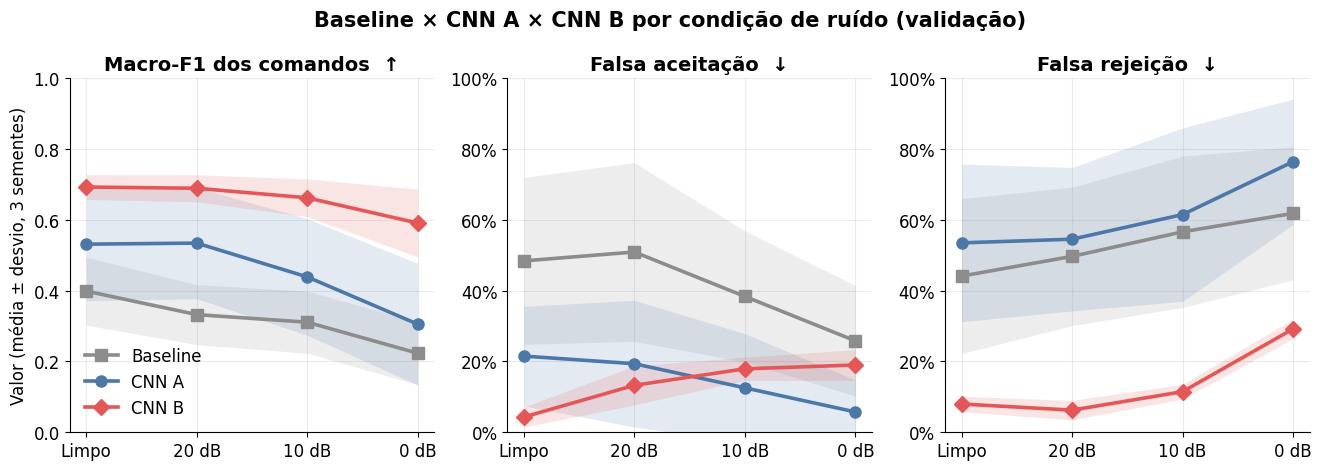

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
titulos = {"macroF1": "Macro-F1 dos comandos  ↑", "FA": "Falsa aceitação  ↓", "FR": "Falsa rejeição  ↓"}
x = np.arange(len(CONDS))
for ax, met in zip(axs, ["macroF1", "FA", "FR"]):
    for m in MOD_RN:
        mu = resumo.loc[m][(met, "mean")].values; sd = resumo.loc[m][(met, "std")].fillna(0).values
        ax.plot(x, mu, marker=MARC[m], ms=8, lw=2.6, color=CORES[m], label=m)
        ax.fill_between(x, mu - sd, mu + sd, color=CORES[m], alpha=0.15, lw=0)
    ax.set_xticks(x, EIXO); ax.set_ylim(0, 1); ax.set_title(titulos[met])
    ax.yaxis.set_major_formatter(plt.FuncFormatter(
        (lambda v, _: f"{v:.1f}") if met == "macroF1" else (lambda v, _: f"{v:.0%}")))
axs[0].set_ylabel("Valor (média ± desvio, 3 sementes)")
axs[0].legend(loc="lower left")
fig.suptitle(f"Baseline × CNN A × CNN B por condição de ruído ({NOME_PART})", fontsize=15, fontweight="bold", y=1.03)
salvar("rn_linhas_por_ruido")

## 2. Falsa aceitação: o efeito da classe "fora"

Barras com a FA média de cada modelo; a anotação mostra quanto a CNN B reduz em relação à CNN A.

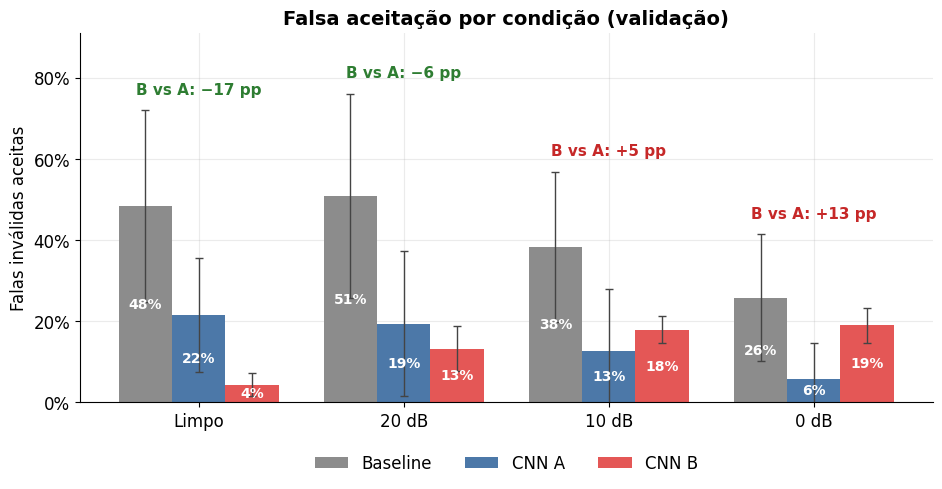

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.8))
w = 0.26
for i, m in enumerate(MOD_RN):
    mu = resumo.loc[m][("FA", "mean")].values; sd = resumo.loc[m][("FA", "std")].fillna(0).values
    b = ax.bar(x + (i - 1) * w, mu, w, yerr=sd, capsize=3, color=CORES[m], label=m,
               error_kw=dict(ecolor="#444", lw=1))
    ax.bar_label(b, labels=[f"{v:.0%}" for v in mu], label_type="center", color="white",
                 fontsize=10, fontweight="bold")
fa_a, fa_b = resumo.loc["CNN A"][("FA", "mean")].values, resumo.loc["CNN B"][("FA", "mean")].values
fa_tab = resumo.xs("FA", axis=1, level=0)
topo = (fa_tab["mean"] + fa_tab["std"].fillna(0)).groupby(level=1).max().reindex(CONDS).values
for xi, a, b, t in zip(x, fa_a, fa_b, topo):
    txt = f"B vs A: −{(a - b) * 100:.0f} pp" if a >= b else f"B vs A: +{(b - a) * 100:.0f} pp"
    ax.text(xi, t + 0.04, txt, ha="center", fontsize=11, fontweight="bold",
            color="#2E7D32" if a - b >= 0.02 else "#C62828")
ax.set_xticks(x, EIXO); ax.set_ylim(0, min(1.1, topo.max() + 0.15))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Falas inválidas aceitas"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax.set_title(f"Falsa aceitação por condição ({NOME_PART})")
salvar("rn_barras_fa")

## 3. A troca entre aceitar falas inválidas e reconhecer comandos

Cada ponto é um modelo em uma condição de ruído. O canto superior esquerdo é o ideal: F1 alto e FA baixa.

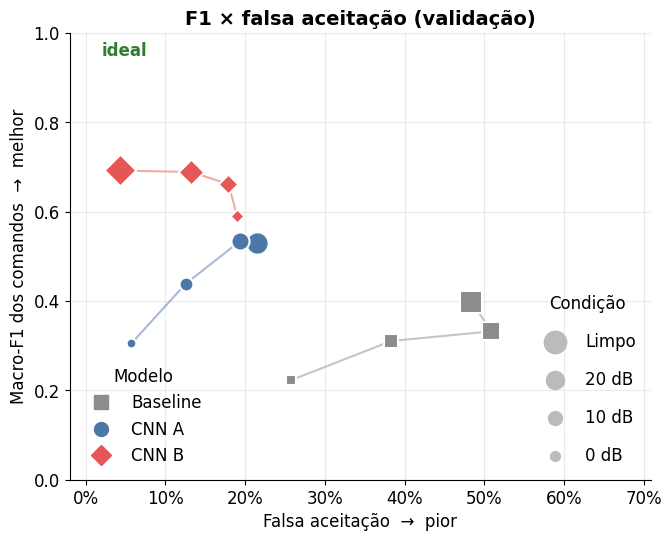

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 5.8))
tam = {"limpo": 260, "20dB": 170, "10dB": 100, "0dB": 50}
for m in MOD_RN:
    fa, f1 = resumo.loc[m][("FA", "mean")].values, resumo.loc[m][("macroF1", "mean")].values
    ax.plot(fa, f1, color=CORES[m], lw=1.5, alpha=0.5)
    for c, a, f in zip(CONDS, fa, f1):
        ax.scatter(a, f, s=tam[c], color=CORES[m], marker=MARC[m], edgecolor="white", lw=1.5, zorder=3)
from matplotlib.lines import Line2D
leg1 = ax.legend([Line2D([], [], color=CORES[m], marker=MARC[m], ms=10, lw=0) for m in MOD_RN], MOD_RN,
                 title="Modelo", loc="lower left")
ax.add_artist(leg1)
ax.legend([plt.scatter([], [], s=tam[c], color="#BBB") for c in CONDS], EIXO, title="Condição",
          loc="lower right", labelspacing=1.2)
ax.set_xlabel("Falsa aceitação  →  pior"); ax.set_ylabel("Macro-F1 dos comandos  →  melhor")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlim(-0.02, min(1, resumo.xs("FA", axis=1, level=0)["mean"].max() + 0.2)); ax.set_ylim(0, 1)
ax.annotate("ideal", (0.02, 0.95), color="#2E7D32", fontweight="bold")
ax.set_title(f"F1 × falsa aceitação ({NOME_PART})")
salvar("rn_dispersao_f1_fa")

## 4. Critério de decisão do M1

A classe "fora" traz vantagem se a CNN B reduzir a FA em **≥ 2 pp** sem perder **mais de 2 pp** de macro-F1.

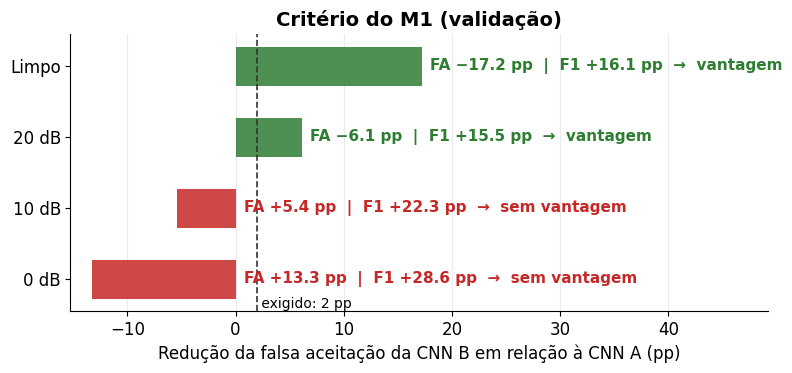

In [6]:
linhas = []
for c in CONDS:
    a, b = resumo.loc[("CNN A", c)], resumo.loc[("CNN B", c)]
    dfa = (a[("FA", "mean")] - b[("FA", "mean")]) * 100
    df1 = (b[("macroF1", "mean")] - a[("macroF1", "mean")]) * 100
    linhas.append([c, dfa, df1, dfa >= 2 and df1 >= -2])
crit = pd.DataFrame(linhas, columns=["cond", "red_FA", "var_F1", "ok"])

fig, ax = plt.subplots(figsize=(9, 3.6))
for i, r in crit.iterrows():
    cor = "#2E7D32" if r.ok else "#C62828"
    ax.barh(i, r.red_FA, color=cor, alpha=0.85, height=0.55)
    fa_txt = f"FA {-r.red_FA:+.1f} pp".replace("-", "−")
    f1_txt = f"F1 {r.var_F1:+.1f} pp".replace("-", "−")
    ax.text(max(r.red_FA, 0) + 0.8, i, f"{fa_txt}  |  {f1_txt}  →  {'vantagem' if r.ok else 'sem vantagem'}",
            va="center", ha="left", fontsize=11, color=cor, fontweight="bold")
ax.axvline(2, color="#333", ls="--", lw=1.2); ax.text(2, len(CONDS) - 0.55, " exigido: 2 pp", fontsize=10, va="bottom")
ax.set_yticks(range(len(CONDS)), EIXO); ax.invert_yaxis()
ax.set_xlim(min(0, crit.red_FA.min()) - 2, max(crit.red_FA.max(), 2) + 32)
ax.set_xlabel("Redução da falsa aceitação da CNN B em relação à CNN A (pp)")
ax.set_title(f"Critério do M1 ({NOME_PART})"); ax.grid(axis="y", visible=False)
salvar("rn_criterio_m1")

## 5. Matrizes de confusão

Calculadas a partir das probabilidades salvas, **somando as 3 sementes**. As linhas são a classe real
(6 comandos + fala fora do escopo); as colunas, a decisão do sistema, incluindo **rejeitar**.
Para a linha "fora", rejeitar é o acerto. A diagonal (acertos) fica em verde e os erros em vermelho.

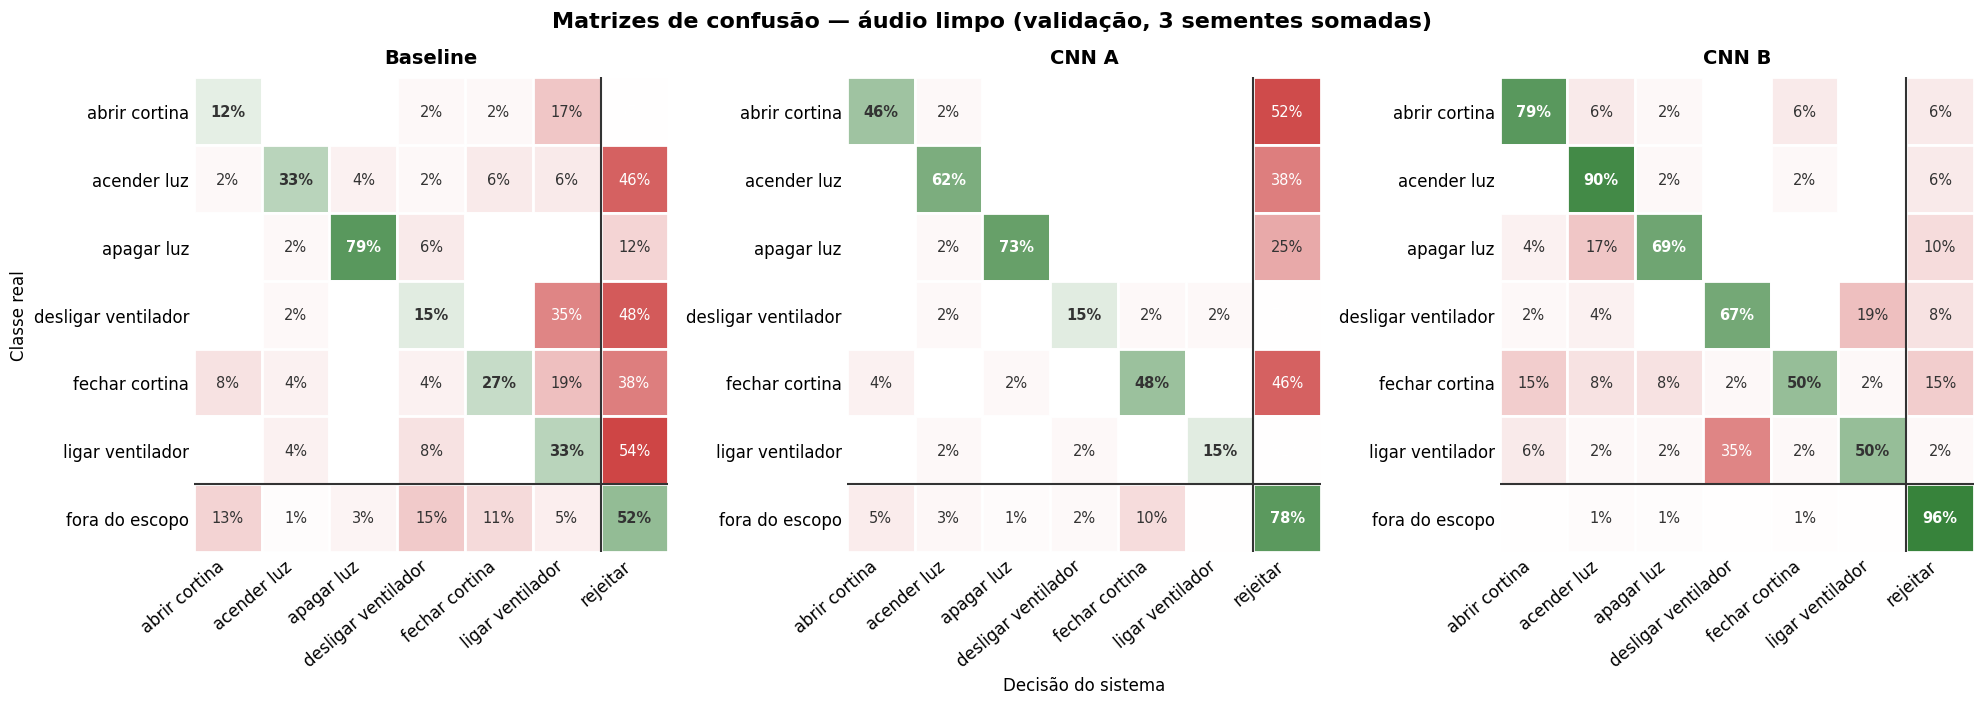

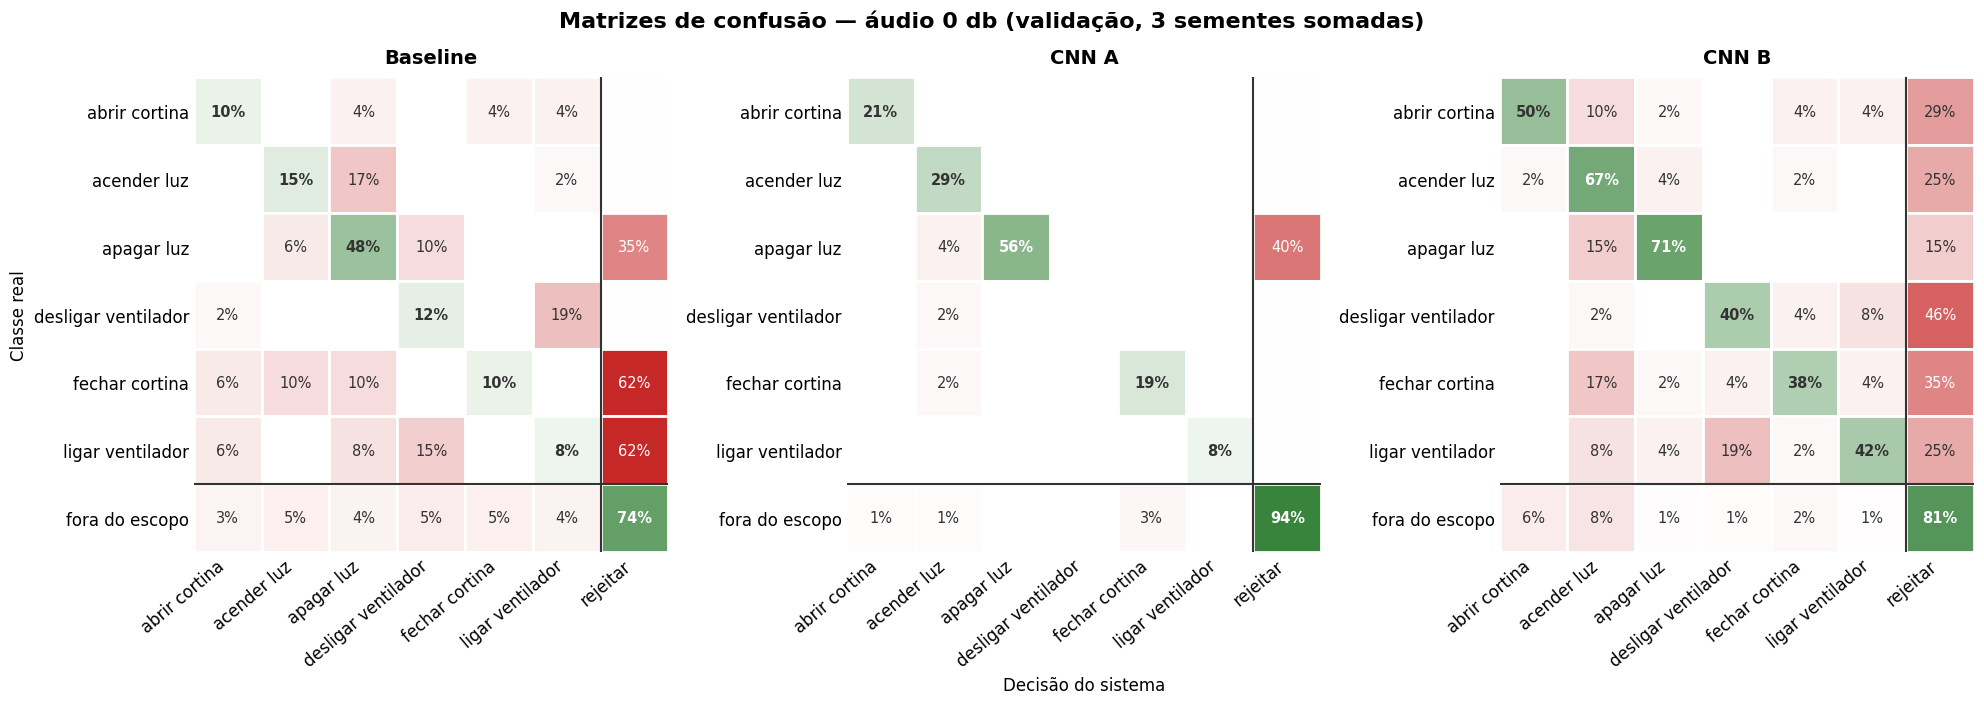

In [7]:
probs = pd.concat([pd.read_csv(f"{BL}/probabilidades_baseline.csv"),
                   pd.read_csv(f"{CN}/probabilidades_cnn.csv")], ignore_index=True)
probs = probs[probs.particao == PART]
COMANDOS = sorted(c[2:] for c in probs.columns if c.startswith("p_") and c != "p_fora")
LIN = COMANDOS + ["fora"]; COL = COMANDOS + ["rejeitado"]
ROT = lambda s: {"fora": "fora do escopo", "rejeitado": "rejeitar"}.get(s, s.replace("_", " "))

def decisoes(d, modelo):
    pc = d[[f"p_{c}" for c in COMANDOS]].values
    conf, pred = pc.max(1), np.array(COMANDOS)[pc.argmax(1)]
    pode = np.ones(len(d), bool)
    if modelo == "CNN B":                              # "fora" é a classe mais provável → rejeita
        pode = d[[f"p_{c}" for c in COMANDOS] + ["p_fora"]].values.argmax(1) < len(COMANDOS)
    return np.where(pode & (conf >= d["limiar"].values), pred, "rejeitado")

def matriz(modelo, cond):
    d = probs[(probs.modelo == modelo) & (probs.cond == cond)]
    cm = pd.crosstab(pd.Categorical(d["rotulo"], LIN), pd.Categorical(decisoes(d, modelo), COL), dropna=False)
    return cm.values

def desenhar(ax, cm, titulo):
    frac = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    acerto = np.zeros_like(frac, bool); acerto[range(len(COMANDOS)), range(len(COMANDOS))] = True; acerto[-1, -1] = True
    verde = mcolors.LinearSegmentedColormap.from_list("v", ["#FFFFFF", "#2E7D32"])
    verm = mcolors.LinearSegmentedColormap.from_list("r", ["#FFFFFF", "#C62828"])
    for i in range(frac.shape[0]):
        for j in range(frac.shape[1]):
            v = frac[i, j]; cmap = verde if acerto[i, j] else verm
            ax.add_patch(Rectangle((j, i), 1, 1, color=cmap(min(v * (1 if acerto[i, j] else 1.6), 1)), ec="white", lw=2))
            if v >= 0.005:
                ax.text(j + 0.5, i + 0.5, f"{v:.0%}", ha="center", va="center", fontsize=10.5,
                        color="white" if v > (0.55 if acerto[i, j] else 0.35) else "#333",
                        fontweight="bold" if acerto[i, j] else "normal")
    ax.set_xlim(0, len(COL)); ax.set_ylim(len(LIN), 0); ax.set_aspect("equal"); ax.grid(False)
    ax.set_xticks(np.arange(len(COL)) + 0.5, [ROT(c) for c in COL], rotation=40, ha="right")
    ax.set_yticks(np.arange(len(LIN)) + 0.5, [ROT(c) for c in LIN])
    ax.axhline(len(COMANDOS), color="#333", lw=1.5); ax.axvline(len(COMANDOS), color="#333", lw=1.5)
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(length=0); ax.set_title(titulo, pad=10)

for cond, nome in [("limpo", "limpo"), ("0dB", "0dB")]:
    fig, axs = plt.subplots(1, 3, figsize=(20, 6.8))
    for ax, m in zip(axs, MOD_RN):
        desenhar(ax, matriz(m, cond), m)
    axs[0].set_ylabel("Classe real"); axs[1].set_xlabel("Decisão do sistema")
    fig.suptitle(f"Matrizes de confusão — áudio {EIXO[CONDS.index(cond)].lower()} ({NOME_PART}, 3 sementes somadas)",
                 fontsize=16, fontweight="bold", y=1.0)
    plt.tight_layout(); salvar(f"rn_confusao_{nome}")

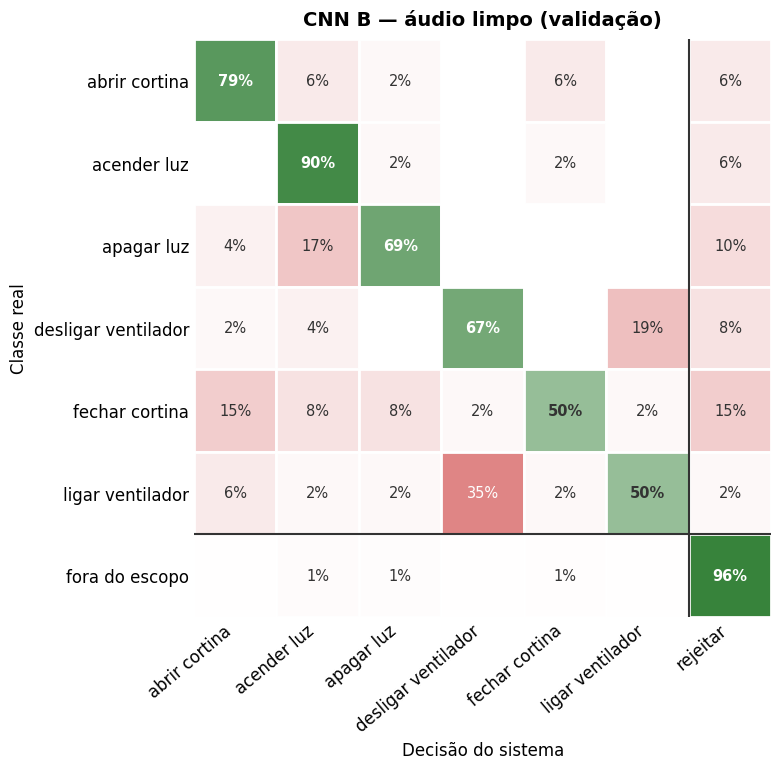

In [8]:
# Uma matriz grande, só da CNN B no áudio limpo, para um slide inteiro
fig, ax = plt.subplots(figsize=(8.5, 7.5))
desenhar(ax, matriz("CNN B", "limpo"), f"CNN B — áudio limpo ({NOME_PART})")
ax.set_ylabel("Classe real"); ax.set_xlabel("Decisão do sistema")
salvar("rn_confusao_cnnb_limpo_grande")

## 6. Machine Learning: KNN e SVM

Resultados do trabalho de ML (7 classes, sem limiar). Linhas tracejadas: treino só com áudio limpo;
linhas cheias: treino com aumento de dados por ruído.

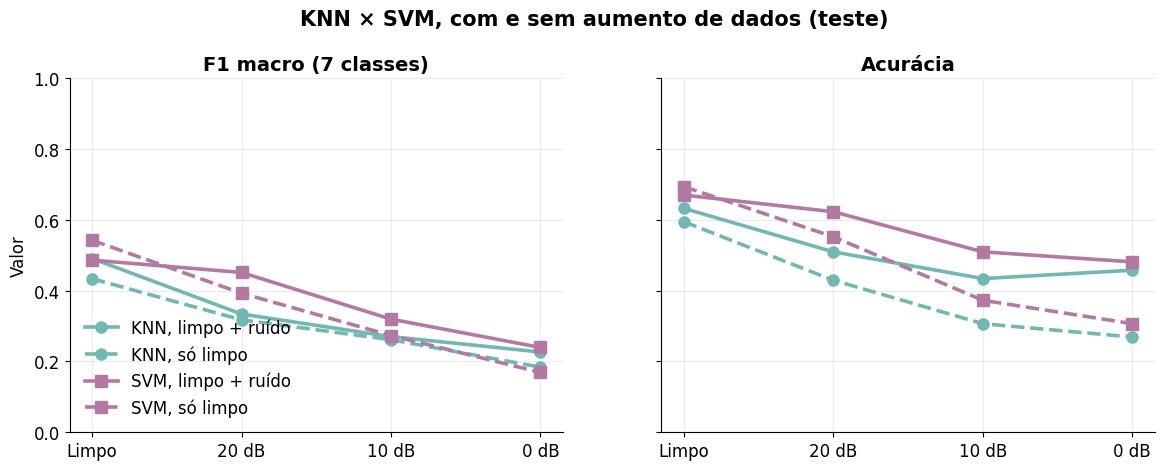

In [9]:
arq = f"{ML}/resultados_ml_teste.csv" if os.path.exists(f"{ML}/resultados_ml_teste.csv") else f"{ML}/resultados_ml_val.csv"
ml = pd.read_csv(arq); NOME_ML = "teste" if "teste" in arq else "validação"
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, met, tit in zip(axs, ["f1", "acuracia"], ["F1 macro (7 classes)", "Acurácia"]):
    for (m, t), g in ml.groupby(["modelo", "treino"]):
        g = g.set_index("cond").reindex(CONDS)
        ax.plot(EIXO, g[met], color=CORES[m], marker=MARC[m], ms=8, lw=2.6,
                ls="-" if "ruído" in t else "--", label=f"{m}, {t.lower()}")
    ax.set_title(tit); ax.set_ylim(0, 1)
axs[0].legend(loc="lower left"); axs[0].set_ylabel("Valor")
fig.suptitle(f"KNN × SVM, com e sem aumento de dados ({NOME_ML})", fontsize=15, fontweight="bold", y=1.03)
salvar("ml_linhas_por_ruido")

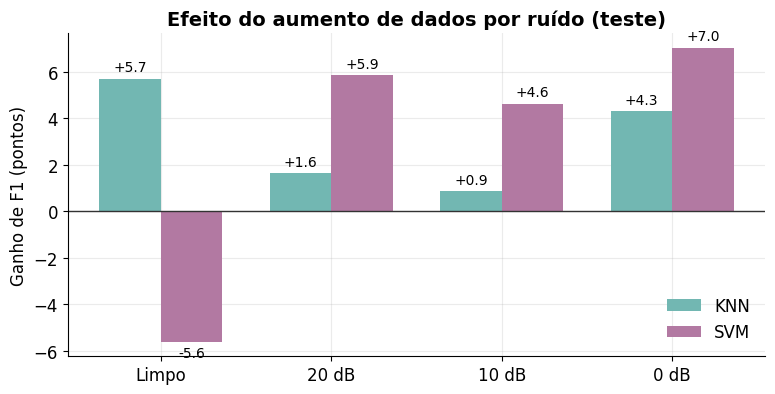

In [10]:
# Ganho do aumento de dados por ruído (F1 do treino com ruído − F1 do treino só limpo)
fig, ax = plt.subplots(figsize=(9, 4.2)); w = 0.36
for i, m in enumerate(["KNN", "SVM"]):
    g = ml[ml.modelo == m].pivot_table(index="cond", columns="treino", values="f1").reindex(CONDS)
    ganho = (g["Limpo + ruído"] - g["Só limpo"]) * 100
    b = ax.bar(np.arange(4) + (i - 0.5) * w, ganho, w, color=CORES[m], label=m)
    ax.bar_label(b, labels=[f"{v:+.1f}" for v in ganho], padding=3, fontsize=10)
ax.axhline(0, color="#333", lw=1); ax.set_xticks(range(4), EIXO)
ax.set_ylabel("Ganho de F1 (pontos)"); ax.legend()
ax.set_title(f"Efeito do aumento de dados por ruído ({NOME_ML})")
salvar("ml_ganho_aumento")

## 7. Tabela-resumo das redes neurais

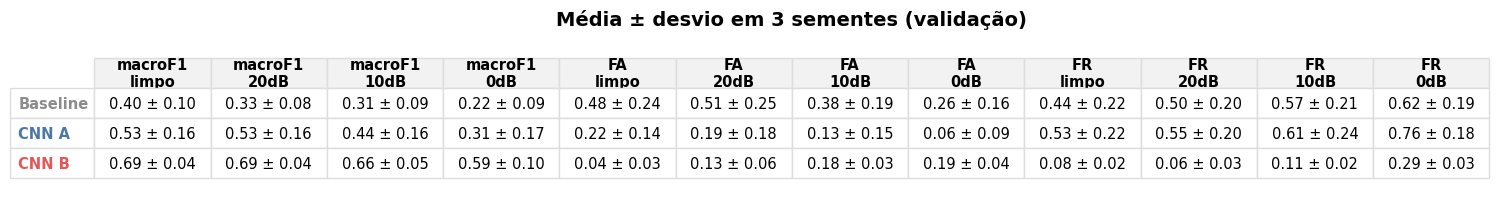

macroF1                                                  FA  \
                limpo         20dB         10dB          0dB        limpo   
Baseline  0.40 ± 0.10  0.33 ± 0.08  0.31 ± 0.09  0.22 ± 0.09  0.48 ± 0.24   
CNN A     0.53 ± 0.16  0.53 ± 0.16  0.44 ± 0.16  0.31 ± 0.17  0.22 ± 0.14   
CNN B     0.69 ± 0.04  0.69 ± 0.04  0.66 ± 0.05  0.59 ± 0.10  0.04 ± 0.03   

                                                          FR               \
                 20dB         10dB          0dB        limpo         20dB   
Baseline  0.51 ± 0.25  0.38 ± 0.19  0.26 ± 0.16  0.44 ± 0.22  0.50 ± 0.20   
CNN A     0.19 ± 0.18  0.13 ± 0.15  0.06 ± 0.09  0.53 ± 0.22  0.55 ± 0.20   
CNN B     0.13 ± 0.06  0.18 ± 0.03  0.19 ± 0.04  0.08 ± 0.02  0.06 ± 0.03   

                                    
                 10dB          0dB  
Baseline  0.57 ± 0.21  0.62 ± 0.19  
CNN A     0.61 ± 0.24  0.76 ± 0.18  
CNN B     0.11 ± 0.02  0.29 ± 0.03

In [11]:
tab = pd.DataFrame({(met, c): [f"{resumo.loc[(m, c), (met, 'mean')]:.2f} ± {resumo.loc[(m, c), (met, 'std')]:.2f}"
                                for m in MOD_RN] for met in ["macroF1", "FA", "FR"] for c in CONDS}, index=MOD_RN)
fig, ax = plt.subplots(figsize=(18, 2.2)); ax.axis("off")
cab = [f"{met}\n{c}" for met, c in tab.columns]
t = ax.table(cellText=tab.values, rowLabels=tab.index, colLabels=cab, loc="center", cellLoc="center")
t.auto_set_font_size(False); t.set_fontsize(10.5); t.scale(1, 1.8)
for (r, c), cel in t.get_celld().items():
    cel.set_edgecolor("#DDD")
    if r == 0: cel.set_facecolor("#F2F2F2"); cel.set_text_props(fontweight="bold")
    if c == -1: cel.set_text_props(color=CORES.get(cel.get_text().get_text(), "#000"), fontweight="bold")
ax.set_title(f"Média ± desvio em 3 sementes ({NOME_PART})", fontweight="bold")
salvar("rn_tabela_resumo")
tab

In [12]:
# Copia as figuras para o Drive
!mkdir -p "$BASE/figuras_apresentacao" && cp figuras_apresentacao/*.png "$BASE/figuras_apresentacao/"
!ls "$BASE/figuras_apresentacao"

ml_ganho_aumento.png		   rn_confusao_limpo.png
ml_linhas_por_ruido.png		   rn_criterio_m1.png
rn_barras_fa.png		   rn_dispersao_f1_fa.png
rn_confusao_0dB.png		   rn_linhas_por_ruido.png
rn_confusao_cnnb_limpo_grande.png  rn_tabela_resumo.png
